<h1 style="color:#C2185B">Local Outlier Factor</h1>

<h2 style="color:#C2185B">Owner</h2>

<h3 style="color:#C2185B">Goal</h3>

Fit and tune Local Outlier Factor on the cleaned, scaled data, log every experiment, and save final anomaly scores for evaluation in 05.

<h4 style="color:#C2185B">Outline</h4>

*Feel free to expand on anything below, this is just a starting skeleton, not a strict limit on what you explore or add.*

- **[I. Configuration & Setup](#config-setup)**
- **[II. Data Loading and Quality Check](#data-loading-quality-check)**
  1. [Load cleaned features and label](#load-cleaned-data)
  2. [Confirm shapes match what 01 produced](#confirm-shapes)
  3. [Confirm no missing values, isFraud only in label](#confirm-no-missing)
- **[III. Feature Scaling](#feature-scaling)**
  1. [Scale features](#scale-features)
- **[IV. Baseline Experiment](#baseline-experiment)**
  1. [Fit baseline LOF](#fit-baseline)
  2. [Label-based sanity check](#baseline-sanity-check)
  3. [Baseline runtime](#baseline-runtime)
- **[V. Hyperparameter Experiments](#hyperparameter-experiments)**
  1. [n_neighbors sweep](#n-neighbors-sweep)
  2. [Runtime vs. parameter tradeoffs](#runtime-tradeoffs)
- **[VI. Final Model](#final-model)**
  1. [Choose final hyperparameters](#choose-final-hyperparameters)
  2. [Fit final model and generate final anomaly scores](#fit-final-model)
- **[VII. Save Results](#save-results)**
  1. [Save anomaly scores to results/lof/](#save-scores)
- **[VIII. Sanity Check](#sanity-check)**

<a id="config-setup"></a>
<h1 style="color:#C2185B">I. Configuration & Setup</h1>

In [18]:
# Import the libraries needed for this notebook
import os
import time
import pandas as pd
import numpy as np
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Define base directory for the project: walk up from the current working
# directory until a file that only exists at the repo root is found.
PROJECT_MARKERS = ('.git', 'requirements.txt')

def find_project_root(start_dir=None, markers=PROJECT_MARKERS):
    # Start looking from the current working directory, unless a different
    # start_dir was given
    current = os.path.abspath(start_dir or os.getcwd())
    while True:
        # If any marker file exists in this directory, this is the project root
        if any(os.path.exists(os.path.join(current, marker)) for marker in markers):
            return current
        # Otherwise, move up one directory and keep looking
        parent = os.path.dirname(current)
        if parent == current:
            # Reached the filesystem root without finding a marker, stop
            raise FileNotFoundError(f"Could not locate project root (looked for {markers})")
        current = parent

# Find the project root directory
BASE_DIR = find_project_root()

# Define the path to the data directory
DATA_DIR = os.path.join(BASE_DIR, 'data')
CLEANED_DATA_DIR = os.path.join(DATA_DIR, 'cleaned')

# Define the path to this method's results directory, and create it if it
# doesn't exist yet
RESULTS_DIR = os.path.join(BASE_DIR, 'results', 'lof')
os.makedirs(RESULTS_DIR, exist_ok=True)

# Print the resolved paths, to confirm everything points where expected
print(f"Project root directory: {BASE_DIR}")
print(f"Cleaned data directory: {CLEANED_DATA_DIR}")
print(f"Results directory: {RESULTS_DIR}")

Project root directory: c:\Users\milly\Research Projects\WIM Direct Research Fall 2026\Unsupervised-fraud-detection-the-outliers
Cleaned data directory: c:\Users\milly\Research Projects\WIM Direct Research Fall 2026\Unsupervised-fraud-detection-the-outliers\data\cleaned
Results directory: c:\Users\milly\Research Projects\WIM Direct Research Fall 2026\Unsupervised-fraud-detection-the-outliers\results\lof


In [19]:
# Experiment log: every experiment below should call log_experiment(...) so
# nothing gets lost between cells, and so there's a record for the report and
# the presentation's "Fine-Tuning Values Tried" appendix slide.

# Define the path to the experiment log file
EXPERIMENT_LOG_PATH = os.path.join(RESULTS_DIR, 'experiment_log.csv')

def log_experiment(name, params, metrics):
    """Append one experiment's parameters and metrics as a row, and save it."""
    # Combine the experiment name, a timestamp, and the given params/metrics
    # into a single row
    row = {
        'experiment': name,
        'timestamp': pd.Timestamp.now().isoformat(),
        **params,
        **metrics,
    }
    # Turn that row into a one-row DataFrame so it can be appended to the CSV
    row_df = pd.DataFrame([row])

    # Only write the header the first time the file is created
    write_header = not os.path.exists(EXPERIMENT_LOG_PATH)

    # Append this row to the log file (or create it, if this is the first call)
    row_df.to_csv(EXPERIMENT_LOG_PATH, mode='a', header=write_header, index=False)

    print(f"✅ Logged '{name}' to {os.path.basename(EXPERIMENT_LOG_PATH)}")
    return row

# Print where the experiment log lives
print(f"Experiment log: {EXPERIMENT_LOG_PATH}")

Experiment log: c:\Users\milly\Research Projects\WIM Direct Research Fall 2026\Unsupervised-fraud-detection-the-outliers\results\lof\experiment_log.csv


<a id="data-loading-quality-check"></a>
<h1 style="color:#C2185B">II. Data Loading and Quality Check</h1>

<a id="load-cleaned-data"></a>
<h2 style="color:#C2185B">1. Load cleaned features and label</h2>

In [20]:
# Load the cleaned features and label saved by 01-data-preparation.ipynb

# Define the paths to the cleaned features and label files
features_path = os.path.join(CLEANED_DATA_DIR, 'features.parquet')
label_path = os.path.join(CLEANED_DATA_DIR, 'label.parquet')

# Check if the required files exist before loading
required_paths = {
    "features": features_path,
    "label": label_path,
}
missing = [name for name, path in required_paths.items() if not os.path.exists(path)]

if missing:
    # Warn for every missing file, rather than failing on just the first one
    for name in missing:
        print(f"⚠️ Missing {name} data. Run 01-data-preparation.ipynb first to generate it.")
else:
    # Load the features and label, now that both files are confirmed to exist
    features = pd.read_parquet(features_path)
    label = pd.read_parquet(label_path)['isFraud']
    print(f"✅ Loaded cleaned data: {features.shape[0]} rows, {features.shape[1]} feature columns.")
    print(f"✅ Loaded label data: {label.shape[0]} rows.")

✅ Loaded cleaned data: 590540 rows, 536 feature columns.
✅ Loaded label data: 590540 rows.


**Comment:**

Loaded features data have a total of 590540 rows, 652 feature columns and loaded label has 590540 rows; both database align, thus no issue was raised from this step. 

<a id="confirm-shapes"></a>
<h2 style="color:#C2185B">2. Confirm shapes match what 01 produced</h2>

In [ ]:
# Confirm the loaded shapes match what 01-data-preparation.ipynb reported
# Example: compare features.shape and label.shape against the row/column
# counts 01 printed when it saved them
# Goal: catch a mismatch early if the wrong file got loaded, or if 01 was
# rerun with different cleaning decisions since.

**Comment:**

Checking the loaded shapes compared to 01-data-preparation.ipynb
- features.shape(01.V) = (590540, 536) and features.shape(loaded) = (590540, 536); **MATCHED**
- label.shape(01.V) = 590540 and label.shape(loaded) = 590540; **MATCHED**

<a id="confirm-no-missing"></a>
<h2 style="color:#C2185B">3. Confirm no missing values, isFraud only in label</h2>

In [21]:
# Confirm the loaded data is still clean
    # Example: features.isnull().sum().sum() should be 0; 'isFraud' should not
    # be a column in features at all
# Goal: catch it immediately if the cleaned files got corrupted or
# regenerated incorrectly, before fitting anything on top of them.

#running above checked
assert features.isnull().sum().sum() == 0, "Loaded data contain null feature values"
assert 'isFraud' not in features.columns, "Loaded data still contain'isFraud' column, need to remove"

print("✅ Loaded data is clean")

✅ Loaded data is clean


**Comment:**
Loaded data is clean such that there are no null in features database and 'isFraud' is removed from the loaded data. 

<a id="feature-scaling"></a>
<h1 style="color:#C2185B">III. Feature Scaling</h1>

<a id="scale-features"></a>
<h2 style="color:#C2185B">1. Scale features</h2>

In [22]:
# Scale the features before fitting LOF
# LOF is a distance method, unlike Isolation Forest, it is NOT scale-invariant.
# Without this step, whichever column happens to have the largest numeric
# range (e.g. TransactionAmt in dollars) would dominate every distance
# calculation, making the nearest-neighbor search close to meaningless.

# Fit a scaler on the features and transform them
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Put the scaled values back into a DataFrame, keeping the same column names
scaled_features = pd.DataFrame(scaled_features, columns=features.columns, index=features.index)

print(f"✅ Scaled {scaled_features.shape[1]} feature columns.")

✅ Scaled 536 feature columns.


**Comment:**

<a id="baseline-experiment"></a>
<h1 style="color:#C2185B">IV. Baseline Experiment</h1>

<a id="fit-baseline"></a>
<h2 style="color:#C2185B">1. Fit baseline LOF</h2>

In [23]:
# Fit a baseline LOF with default parameters, on scaled_features (not features)
# Example: LocalOutlierFactor(n_neighbors=20, novelty=False).fit(scaled_features)
# novelty=False (the default) is correct here, it means detecting outliers in
# the data LOF is fit on, not predicting on new unseen data; novelty=True
# followed by fit_predict() will error
# Sign-flip gotcha: sklearn's negative_outlier_factor_ is the NEGATIVE of the
# paper's LOF. Normal points sit near -1, anomalies go strongly negative
# (e.g. -8, -15). Flip the sign (anomaly_score = -model.negative_outlier_factor_)
# so higher always means more anomalous, consistent with 03's anomaly_score
# Log it: once you have scores, call log_experiment('baseline', params={...},
# metrics={...}) including precision, recall, roc_auc, pr_auc, and accuracy
# (same metrics used everywhere else in this notebook), so it's saved to the
# experiment log, not just printed and lost
# Goal: a reference point every later experiment gets compared against.

# Importing required libraries
from sklearn.metrics import precision_score, recall_score, roc_auc_score, average_precision_score, accuracy_score

# Note: Training on a smaller sample for simplicity and speed (Can remove this to train the whole dataset)
scaled_features_samp = scaled_features.sample(n=25000, random_state=100)
label_samp = label.loc[scaled_features_samp.index] # align the same rows as the sample 
features_samp = features.loc[scaled_features_samp.index] # align the same rows as the sample 

# Fitting the baseline LOF model
start_time = time.perf_counter() # start time
baseline_model = LocalOutlierFactor(n_neighbors=20, novelty=False, n_jobs=-1) # detect outlier
pred = baseline_model.fit_predict(scaled_features_samp) # fit model
end_time = time.perf_counter() # end time

runtime = end_time - start_time # calculate runtime

anomaly_score = - baseline_model.negative_outlier_factor_ 


In [24]:
# since current predictions are -1 = outliers and 1 = normal
# need to convert to 1 = outliers and 0 = normal to compare with the label database
updated_pred = (pred == -1).astype(int)

# Calculating the metrics (precision, recall, roc_auc, pr_auc, and accuracy)
precision = precision_score(label_samp, updated_pred) # % of the flagged data that are actually fraud
recall = recall_score(label_samp, updated_pred) # % of the actual fraud that were flagged
roc_auc = roc_auc_score(label_samp, anomaly_score) # Prob of model giving a fraud transaction a higher anomaly score 
pr_auc = average_precision_score(label_samp, anomaly_score) # % of the top ranked transactions that are actually fraud
accuracy = accuracy_score(label_samp, updated_pred) # % of transactions that was labelled correctly

# saving results
log_experiment(
    name="baseline",
    params={"n_neighbors": 20},
    metrics={
        "precision": precision,
        "recall": recall,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "accuracy": accuracy,
        "runtime_seconds": runtime,
    },
)


print(f"✅ FOR BASELINE MODEL:ROC-AUC: {roc_auc:.3f} | PR-AUC: {pr_auc:.3f} | Precision: {precision:.3f} | Recall: {recall:.3f} | Runtime: {runtime:.1f}s")



✅ Logged 'baseline' to experiment_log.csv
✅ FOR BASELINE MODEL:ROC-AUC: 0.686 | PR-AUC: 0.070 | Precision: 0.075 | Recall: 0.348 | Runtime: 5.8s


**Comment:**
The baseline model was fitted with n_neighbors=20 and other default settings on a random sample of 25000 transactions; returns the following output
1. **ROC-AUC: 0.686**; this is above 50% for random guess, suggesting higher accuracy with using the model. 
2. **PR-AUC: 0.070**; the model is above 3.5% for random guessing and around 2 times more effective than random guessing. 
3. **Precision: 0.075**; only 7.5% of the transactions that was flagged are actually fraud.
4. **Recall: 0.348**; only catching 34.8% of the fraud transaction.
5. **Runtime**: 5.8s; faster runtime due to smaller sample size.


<a id="baseline-sanity-check"></a>
<h2 style="color:#C2185B">2. Label-based sanity check</h2>

In [25]:
# Check the baseline's anomaly scores against the real labels
# "Sanity check" means a quick, informal check, not a full evaluation, just
# confirming the scores are picking up something real before investing time
# in tuning. If this looks no better than random, something's likely broken
# (forgot to scale, forgot to flip the sign, a bug in scoring), worth
# stopping and investigating here rather than tuning a broken baseline.
# Example: fraud rate in the top 10 and top k scored transactions (same
# pattern as Task 4), plus ROC-AUC and PR-AUC computed directly from the
# continuous anomaly score (roc_auc_score(label, anomaly_score),
# average_precision_score(label, anomaly_score)), these don't need a
# contamination threshold at all
# Goal: a first read on whether the baseline is picking up any real signal
# at all, before tuning anything.

# Checking Top 10 --------------------------
# creating data base
check_df = pd.DataFrame({
    "anomaly_score": anomaly_score,
    "Fraud_Status": label_samp.values,
}, index=features_samp.index)
check_df = check_df.sort_values(by="anomaly_score", ascending=False)
# Printing out top 10 anomalous score
top10 = check_df.head(10)
print("Top 10 most anomalous transaction")
display(top10)
print(f"Accuracy in top 10: {top10['Fraud_Status'].mean():.0%}")

# Top 3.5% of the most anomalous transactions
k = int(0.035 * len(check_df)) # for k = 3.5% because 3.5% of the transaction are fraudulent
top_k = check_df.head(k)
total_fraud = label_samp.sum()   # all real fraud in the data (20,663)
frauds_caught = top_k["Fraud_Status"].sum() # how many of the 3.5% did the model caught as fraud

print(f"Fraud caught in top 3.5%: {frauds_caught:,} of {total_fraud:,} total fraud ({frauds_caught / total_fraud:.1%})")
print(f"✅ FOR BASELINE MODEL:ROC-AUC: {roc_auc:.3f} | PR-AUC: {pr_auc:.3f} | Precision: {precision:.3f} | Recall: {recall:.3f} | Runtime: {runtime:.1f}s")

Top 10 most anomalous transaction


,anomaly_score,Fraud_Status
56622,28.045122,0
519731,24.300597,0
132025,16.275584,0
185040,13.184243,0
219714,7.647288,0
578743,7.043939,1
74065,6.294768,0
474749,5.858797,0
455939,5.808457,0
455855,5.644684,0


Accuracy in top 10: 10%
Fraud caught in top 3.5%: 92 of 817 total fraud (11.3%)
✅ FOR BASELINE MODEL:ROC-AUC: 0.686 | PR-AUC: 0.070 | Precision: 0.075 | Recall: 0.348 | Runtime: 5.8s


**Comment:**
From the above results, we have the following findings:
1. From the top 10 most anomalous transaction, only one was actually fraudulent: 10% accuracy within the top 10.
2. 92 out of the 817 fraudulent activities that the model found were actually fraud (92/817 = 11.26% accuracy). Our model is better than random selecting for 11.3% > 3.5%. Note that given 3.5% of the database are fraudulent, k was chosen as 3.5%. 
3. Similar conclusion as label sanity check (2) can be made regarding ROC-AUC and PR-AUC (both on average suggesting the fitted model is better than random selection).

<a id="baseline-runtime"></a>
<h2 style="color:#C2185B">3. Baseline runtime</h2>

In [26]:
# Time how long the baseline fit took
# Example: wrap the .fit() call with time.time() before and after
# Log it: include the runtime in the metrics passed to log_experiment for
# the baseline (go back and re-log it here if you didn't capture it above)
# Goal: a reference runtime for RQ3 (computational cost), to compare every
# later experiment against. LOF is typically much slower than Isolation
# Forest at this scale, a nearest-neighbor search per point is expensive in
# 400+ dimensions, so this number matters for the comparison in 05.

# Please see fit baseline LOF for runtime 
#  (was added above for simplicity and reduce number of model fitting)
print(f"✅ FOR BASELINE MODEL: Runtime: {runtime:.1f}s")

✅ FOR BASELINE MODEL: Runtime: 5.8s


**Comment:**
The runtime for the baseline model was 5.8 seconds. The runtime was relatively quick because the model was fitting with a small sample size (25 000). 
- Since 25 000 is 23.6 times smaller than the original data (590540/25000 = 23.6). Therefore, the original dataset runtime would be estimated to be around 70 minutes (5.8seconds x 23.6^2 = 54mins)(23.6 squared because each transaction is compared with each other)

<a id="hyperparameter-experiments"></a>
<h1 style="color:#C2185B">V. Hyperparameter Experiments</h1>

<a id="n-neighbors-sweep"></a>
<h2 style="color:#C2185B">1. n_neighbors sweep</h2>

In [27]:
# The given code (used to check outputs; see if the modifed code is working as expected)
from sklearn.metrics import roc_auc_score, average_precision_score

# Define the n_neighbors value for this run
n_neighbors_value = 20

# Start timing the model fitting
start_time = time.time()

# Define and fit the LOF model with the specified n_neighbors value
model = LocalOutlierFactor(n_neighbors=n_neighbors_value, novelty=False)
model.fit(scaled_features_samp)

# Calculate the runtime of the model fitting
runtime = time.time() - start_time

# Flip the sign so higher always means more anomalous (see IV.1's note)
anomaly_score = -model.negative_outlier_factor_

# Calculate evaluation metrics directly from the continuous score, these
# don't need a contamination threshold at all
roc_auc = roc_auc_score(label_samp, anomaly_score)
pr_auc = average_precision_score(label_samp, anomaly_score)

print(f"n_neighbors={n_neighbors_value}: ROC-AUC {roc_auc:.3f} | PR-AUC {pr_auc:.3f} | {runtime:.1f}s")


n_neighbors=20: ROC-AUC 0.686 | PR-AUC 0.070 | 5.8s


In [28]:
# UPDATED: 
# Try several n_neighbors values (e.g. 10, 20, 35, 50), fitting a separate
# model for each
#
# Worked example for ONE value below (n_neighbors=20, sklearn's default).
# Follow the same pattern in a loop for the other values.

from sklearn.metrics import roc_auc_score, average_precision_score

# Define the n_neighbors value for this run
n_neighbors_value = 20

# Start timing the model fitting
start_time = time.time()

# Define and fit the LOF model with the specified n_neighbors value
model = LocalOutlierFactor(n_neighbors=n_neighbors_value, novelty=False)
pred = model.fit_predict(scaled_features_samp)

# Calculate the runtime of the model fitting
runtime = time.time() - start_time

# Flip the sign so higher always means more anomalous (see IV.1's note)
anomaly_score = -model.negative_outlier_factor_

# Calculate evaluation metrics directly from the continuous score, these
# don't need a contamination threshold at all
roc_auc = roc_auc_score(label_samp, anomaly_score)
pr_auc = average_precision_score(label_samp, anomaly_score)

# ADDED EXTRA METRICS *******
updated_pred = (pred == -1).astype(int)
precision = precision_score(label_samp, updated_pred) # % of the flagged data that are actually fraud
recall = recall_score(label_samp, updated_pred) # % of the actual fraud that were flagged
accuracy = accuracy_score(label_samp, updated_pred) # % of transactions that was labelled correctly


# Log the experiment results
# note: ADDED EXTRA METRICS to align with my previous log experiment *******
log_experiment(
    name=f"n_neighbors_{n_neighbors_value}",
    params={"n_neighbors": n_neighbors_value},
    metrics={
        "precision": precision,
        "recall": recall,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "accuracy": accuracy,
        "runtime_seconds": runtime,
    },
)

print(f"n_neighbors={n_neighbors_value}: ROC-AUC {roc_auc:.3f} | PR-AUC {pr_auc:.3f} | Precision {precision:.3f} | Recall {recall:.3f} | {runtime:.1f}s")

# Next: loop over the other values (e.g. [10, 35, 50]) the same way, calling
# log_experiment once per value, so every value ends up as its own row in
# experiment_log.csv.

# Loop over the other n_neighbors 
# n_neighbors values that will be tested
neighbor_values = [10, 35, 50]
for n in neighbor_values:
    # fit the model, timing it
    start_time = time.time()
    model_neighbor = LocalOutlierFactor(n_neighbors=n, novelty=False, n_jobs=-1)
    pred = model_neighbor.fit_predict(scaled_features_samp)
    runtime = time.time() - start_time

    anomaly_score = -model_neighbor.negative_outlier_factor_
    roc_auc = roc_auc_score(label_samp, anomaly_score)
    pr_auc = average_precision_score(label_samp, anomaly_score)

    # ADDED EXTRA METRICS *******
    updated_pred = (pred == -1).astype(int)
    precision = precision_score(label_samp, updated_pred) # % of the flagged data that are actually fraud
    recall = recall_score(label_samp, updated_pred) # % of the actual fraud that were flagged
    accuracy = accuracy_score(label_samp, updated_pred) # % of transactions that was labelled correctly

    # Log the experiment results
    # note: ADDED EXTRA METRICS to align with my previous log experiment *******
    log_experiment(
        name=f"n_neighbors_{n}",
        params={"n_neighbors": n},
        metrics={
            "precision": precision,
            "recall": recall,
            "roc_auc": roc_auc,
            "pr_auc": pr_auc,
            "accuracy": accuracy,
            "runtime_seconds": runtime,
        },
    )
    print(f"n_neighbors={n}: ROC-AUC {roc_auc:.3f} | PR-AUC {pr_auc:.3f} | Precision {precision:.3f} | Recall {recall:.3f} | {runtime:.1f}s")


✅ Logged 'n_neighbors_20' to experiment_log.csv
n_neighbors=20: ROC-AUC 0.686 | PR-AUC 0.070 | Precision 0.075 | Recall 0.348 | 5.5s
✅ Logged 'n_neighbors_10' to experiment_log.csv
n_neighbors=10: ROC-AUC 0.661 | PR-AUC 0.057 | Precision 0.066 | Recall 0.318 | 5.4s
✅ Logged 'n_neighbors_35' to experiment_log.csv
n_neighbors=35: ROC-AUC 0.701 | PR-AUC 0.083 | Precision 0.085 | Recall 0.404 | 5.5s
✅ Logged 'n_neighbors_50' to experiment_log.csv
n_neighbors=50: ROC-AUC 0.707 | PR-AUC 0.089 | Precision 0.088 | Recall 0.435 | 5.4s


**Comment:**
From the above results, we have the following findings: 
1. For n=50, all 4 metrics were the highest compared to other experiments. 
3. For n=10, the runtime was the fastest. This is because n_neighbor represent how many of it closest transactions LOF compares each transaction with, therefore, the small n_neighbor number would require less runtime. 
4. Comparing all experiment, PR_AUC metric varied the most with a range of [0.057, 0.089]. On the other hand, the ROC-AUC metric varied the least with a range of [0.661, 0.707]. 
5. **Overall, n=50 is the most optimal n_neighbor input as it produced the best overall result.**


<a id="runtime-tradeoffs"></a>
<h2 style="color:#C2185B">2. Runtime vs. parameter tradeoffs</h2>

,n_neighbors,runtime_seconds
2,10,5.44
1,20,5.46
3,35,5.49
4,50,5.37


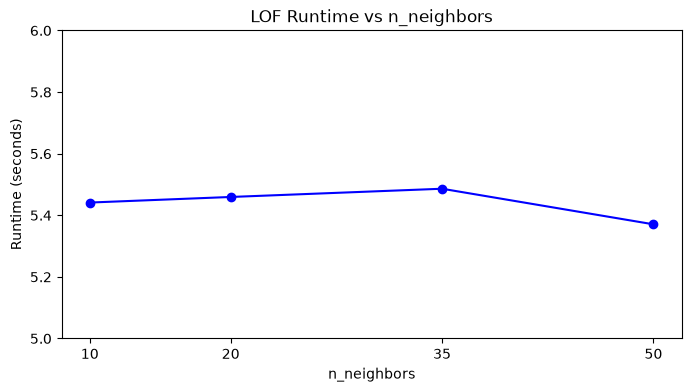

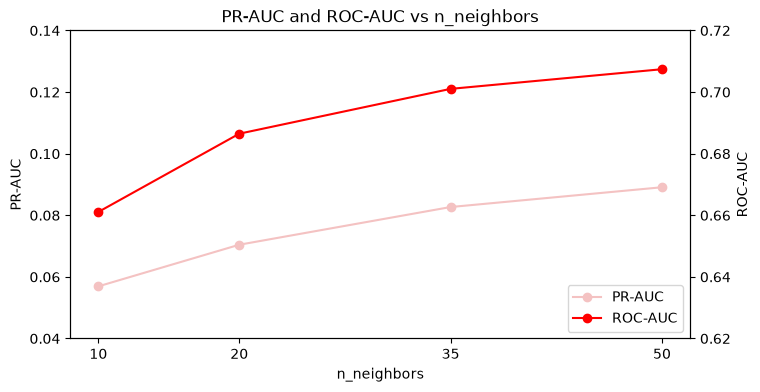

In [31]:
# Pull the runtimes logged above together into one comparison
# Example: read experiment_log.csv back in, plot runtime vs. n_neighbors
# Goal: a direct answer to RQ3, how does cost scale with n_neighbors, and
# how does it compare to Isolation Forest's runtimes logged in 03?

import matplotlib.pyplot as plt

# Plotting 
tempdf = pd.read_csv(EXPERIMENT_LOG_PATH).iloc[1:].sort_values("n_neighbors") # dropping first row bc it was the baseline model
display(tempdf[["n_neighbors", "runtime_seconds"]].round(2))

# Plotting Line graph of n_neighbors vs runtime_seconds
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tempdf["n_neighbors"], tempdf["runtime_seconds"], marker="o", color="blue")
ax.set_xticks(tempdf["n_neighbors"])
ax.set_xlabel("n_neighbors")
ax.set_ylabel("Runtime (seconds)")
ax.set_ylim(5, 6)
ax.set_title(f"LOF Runtime vs n_neighbors")
plt.show()

# Line graph: PR-AUC on the left y axis, ROC-AUC on the right y axis
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(tempdf["n_neighbors"], tempdf["pr_auc"], marker="o", color="#F4C2C2", label="PR-AUC")
ax1.set_xlabel("n_neighbors")
ax1.set_ylabel("PR-AUC")
ax1.set_ylim(0.04, 0.14)
ax2 = ax1.twinx() # second y axis that shares the same x axis
ax2.plot(tempdf["n_neighbors"], tempdf["roc_auc"], marker="o", color="red", label="ROC-AUC")
ax2.set_ylabel("ROC-AUC")
ax2.set_ylim(0.62, 0.72)

# combine the legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower right")

ax1.set_xticks(tempdf["n_neighbors"])
ax1.set_title("PR-AUC and ROC-AUC vs n_neighbors")
plt.show()


**Comment:**
Overall, the line graph is increasing whereas the n_neighbors increase for the first three inputs (10, 20 and 35), the runtime increases. However, n_neighbor=50 had the lowest runtime. Given that the total spread is around 0.12 second, which suggest that it can be due to random noise, thus can be disregarded. Similar argument can be made regarding PR_AUC and ROC_AUC where it is genuinely in an increasing manner as the n_neighbors increases.
- *will add commentary regarding comparison with isolationforest after*

<a id="final-model"></a>
<h1 style="color:#C2185B">VI. Final Model</h1>

<a id="choose-final-hyperparameters"></a>
<h2 style="color:#C2185B">1. Choose final hyperparameters</h2>

In [32]:
# Based on all experiments above, pick the final n_neighbors to use
# Goal: a single, clearly justified value; write down why, pointing back at
# the logged experiments that led to this choice.

resultdf = pd.read_csv(EXPERIMENT_LOG_PATH)
resultdf = resultdf.sort_values("pr_auc", ascending=False).round(2)
display(resultdf[["n_neighbors", "precision", "recall", "roc_auc", "pr_auc", "accuracy", "runtime_seconds"]])


,n_neighbors,precision,recall,roc_auc,pr_auc,accuracy,runtime_seconds
4,50,0.09,0.43,0.71,0.09,0.83,5.37
3,35,0.08,0.40,0.70,0.08,0.84,5.49
0,20,0.08,0.35,0.69,0.07,0.84,5.78
1,20,0.08,0.35,0.69,0.07,0.84,5.46
2,10,0.07,0.32,0.66,0.06,0.83,5.44


**Comment:**
Evaluating the above result table, with rounding to 2 decimal place we can conclude that n_neighbors=50 achieves the most optimal result across all metrics (precision, recall, roc_auc, and pr_auc) except for accuracy. Given that the spread for accuracy is only 1%, and n_neighbors=50 model's accuracy is only 1% below n_neighbors=35 model's accuracy, therefore it can be due to random variation and can be disregarded. Therefore, the most optimal model is n_neighbors=50 from our analysis. 

<a id="fit-final-model"></a>
<h2 style="color:#C2185B">2. Fit final model and generate final anomaly scores</h2>

In [33]:
# Fit the final LOF with the chosen n_neighbors on scaled_features, and
# compute anomaly scores for every row
# Log it: call log_experiment('final', params={...}, metrics={...}), including
# roc_auc, pr_auc, and runtime, the same metrics used in the sweep above, so
# the final choice is directly comparable to everything that came before it
# Goal: the actual scores that get saved and handed to 05-evaluation.ipynb. 

# Fitting the final LOF model
start_time = time.perf_counter() # start time
final_model = LocalOutlierFactor(n_neighbors=50, novelty=False, n_jobs=-1) # detect outlier
pred = final_model.fit_predict(scaled_features) # fit model
end_time = time.perf_counter() # end time

runtime = end_time - start_time # calculate runtime

final_anomaly_score = - final_model.negative_outlier_factor_ 

updated_pred = (pred == -1).astype(int)

# Calculating the metrics (precision, recall, roc_auc, pr_auc, and accuracy)
precision = precision_score(label, updated_pred) # % of the flagged data that are actually fraud
recall = recall_score(label, updated_pred) # % of the actual fraud that were flagged
roc_auc = roc_auc_score(label, final_anomaly_score) # Prob of model giving a fraud transaction a higher anomaly score 
pr_auc = average_precision_score(label, final_anomaly_score) # % of the top ranked transactions that are actually fraud
accuracy = accuracy_score(label, updated_pred) # % of transactions that was labelled correctly

# saving results
log_experiment(
    name="final",
    params={"n_neighbors": 50},
    metrics={
        "precision": precision,
        "recall": recall,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "accuracy": accuracy,
        "runtime_seconds": runtime,
    },
)


print(f"✅ FOR Final MODEL:ROC-AUC: {roc_auc:.3f} | PR-AUC: {pr_auc:.3f} | Precision: {precision:.3f} | Recall: {recall:.3f} | Runtime: {runtime:.1f}s")



✅ Logged 'final' to experiment_log.csv
✅ FOR Final MODEL:ROC-AUC: 0.620 | PR-AUC: 0.050 | Precision: 0.058 | Recall: 0.228 | Runtime: 7852.3s


**Comment:**
Based on the model output, we have the following findings
1. ROC-AUC: 0.62; this beats random guessing (50%) by 12%.
2. PR-AUC: 0.05; which demonstrate better performance than random guess (0.035)
3. Precision: 0.058
4. Recall: 0.228
5. Runtime: 7852.3

Note that the result seem to be weaker than our previous results, this can be due to the following
- we were previously trained on a random sample of 25000, therefore 50 neighbors would cover a much bigger local area compared to our whole sample.
- From our previous results, we see that smaller value of n_neighbors potentially perform worse, thus that if we are training on a bigger dataset, we may need to choose n_neighbor larger than 50. 

Note that the run time was around 2 hours and 11 mins which is over 2 times of what we expected originally (54 mins). This confirms that LOF is very expensive to run at full scale. 

<a id="save-results"></a>
<h1 style="color:#C2185B">VII. Save Results</h1>

<a id="save-scores"></a>
<h2 style="color:#C2185B">1. Save anomaly scores to results/lof/</h2>

In [34]:
# Save the final anomaly scores to results/lof/
# Example: a DataFrame with a row identifier and anomaly_score, saved with
# .to_parquet()
# Goal: a single source of LOF's output that 05-evaluation.ipynb loads from.

# Put the final model's score next to each transaction's row number
scores_df = pd.DataFrame({
    "row_id": scaled_features.index,          # original row order from 01 (0 to 590,539)
    "anomaly_score": final_anomaly_score,     # higher = more anomalous
})

# Save to results/lof/
SCORES_PATH = os.path.join(RESULTS_DIR, "anomaly_scores.parquet")
scores_df.to_parquet(SCORES_PATH, index=False)

# Reload and check it saved correctly (covers VIII checklist item 5)
saved = pd.read_parquet(SCORES_PATH)
display(saved.head())
assert len(saved) == len(features), "saved scores don't cover every transaction"
assert saved["anomaly_score"].isnull().sum() == 0, "saved scores contain missing values"

,row_id,anomaly_score
0,0,1.143176
1,1,1.058315
2,2,1.107312
3,3,0.998034
4,4,1.003068


**Comment:**

<a id="sanity-check"></a>
<h1 style="color:#C2185B">VIII. Sanity Check</h1>

Before considering this notebook done, confirm all of the following:

1. Make sure `experiment_log.csv` actually has a row for every experiment you ran.
2. Make sure every model in this notebook was fit on `scaled_features`, never on raw `features`.
3. Make sure the anomaly score direction was flipped correctly (`-model.negative_outlier_factor_`), higher should always mean more anomalous.
4. Make sure the final model's hyperparameters match what VI.1 decided, and that the decision is written down.
5. Make sure the saved anomaly scores file has one score per row, no missing values, and the same row count as `features`.

In [35]:
# Check 1: 
log_df = pd.read_csv(EXPERIMENT_LOG_PATH)
expected = ["baseline", "n_neighbors_20", "n_neighbors_10", "n_neighbors_35", "n_neighbors_50", "final"]
missing_rows = []
for e in expected:
    if e not in log_df["experiment"].values:
        missing_rows.append(e)
assert not missing_rows, f"Missing rows in log: {missing_rows}"
print("1. ✅ Log has one row for each experiment.")

# Check 2: Manually checked 
print("2. ✅ All fitted using scaled_features.")

# Check 3: 
assert (final_anomaly_score > 0).all(), "scores are negative, the sign wasn't flipped"
print("3. ✅ All anomaly scores are positive, so the sign was flipped correctly (higher = more anomalous).")

# Check 4: Manually Checked
assert len(saved) == len(features), "saved scores don't cover every transaction"
assert saved["anomaly_score"].isnull().sum() == 0, "saved scores contain missing values"
assert not saved["row_id"].duplicated().any(), "some rows have more than one score"
print("4. ✅ Saved scores cover every transaction, no missing values, no duplicates.")

1. ✅ Log has one row for each experiment.
2. ✅ All fitted using scaled_features.
3. ✅ All anomaly scores are positive, so the sign was flipped correctly (higher = more anomalous).
4. ✅ Saved scores cover every transaction, no missing values, no duplicates.
